# Electricity spending percentiles: Qatar and Iceland

How climate change moves electricity spending in two countries over 2080 to 2099, under RCP8.5 and SSP3 (IIASA), with full adaptation. Qatar's spending rises, because it needs more cooling. Iceland's falls, because it needs less heating.

These percentiles need no batches of Monte Carlo projections. For every impact region and year, the run for each climate projection stores the gradient of the result with respect to the 80 regression coefficients, along with the coefficients' covariance matrix. That is enough to give each projection a normal distribution at any province or country. The 33 climate projections, from 21 climate models and 12 pattern-scaled surrogates, are then mixed with their SMME weights, and the percentiles are read off the mixture.

The map at the end shows the change per person in Chile and Austria, at the start and the end of the century, from the whole country down to adm2.

`data/` holds the runs cut to the eight impact regions of Qatar and Iceland, and the median runs also for the 220 regions of Chile and Austria. `prepare_data.py` rebuilds it on Midway3.

In [1]:
import netCDF4
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

import cil_regionalization as cilreg
import data

GCMS = data.gcms()
with netCDF4.Dataset(data.gradient_path(GCMS[0])) as ds:
    YEARS = np.asarray(ds.variables["year"][:])
EARLY, LATE = data.WINDOWS
print(f"{len(GCMS)} climate projections; years {YEARS[0]} to {YEARS[19]} and {YEARS[20]} to {YEARS[-1]}")

33 climate projections; years 2020 to 2039 and 2080 to 2099


## 1. One leaf

A leaf is the run for one climate projection and one scenario. The delta-method tree has two leaves per projection: full adaptation, and histclim, the same run with the climate held at its historical level. The effect of climate change is the difference between them.

In [2]:
gcm, year = "CCSM4", 2090
clim = cilreg.read_gradient_leaf(data.gradient_path(gcm), year=year)
hist = cilreg.read_gradient_leaf(data.gradient_path(gcm, histclim=True), year=year)
regions = clim.regions
print("gradient", clim.gradient.shape, "(coefficient, region)")
print("covariance", clim.vcv.shape)
regions

gradient (80, 8) (coefficient, region)
covariance (80, 80)


['QAT.1',
 'QAT.5',
 'QAT.R30a7711ec96544b9',
 'QAT.Raded92090ad6c843',
 'ISL.3.R5d10609bb3951034',
 'ISL.1.R6254c869d03486f3',
 'ISL.8.R2cc87db221f6ed0a',
 'ISL.R8797959ca4080a3e']

Each leaf also stores the variance of its own run, which is the quadratic form of the gradient with the covariance matrix. Ours agrees with it to the precision of the file, which is float32.

In [3]:
for name, leaf in (("full adaptation", clim), ("histclim", hist)):
    ours = np.einsum("cr,cd,dr->r", leaf.gradient, leaf.vcv, leaf.gradient)
    print(f"{name}: worst relative difference {np.max(np.abs(ours / leaf.stored_variance - 1)):.1e}")

full adaptation: worst relative difference 2.2e-07
histclim: worst relative difference 1.7e-07


The subtraction has to happen on the gradients. Both runs use the same coefficients, so their errors are strongly correlated, and the difference of their variances is not the variance of their difference. For Qatar it comes out negative.

In [4]:
effect = clim.gradient - hist.gradient
pd.DataFrame({
    "variance of the difference": np.einsum("cr,cd,dr->r", effect, clim.vcv, effect),
    "difference of the variances": clim.stored_variance - hist.stored_variance,
}, index=regions)

,variance of the difference,difference of the variances
QAT.1,0.938152,-0.127599
QAT.5,1.026463,-0.054487
QAT.R30a7711ec96544b9,0.934422,-0.101873
QAT.Raded92090ad6c843,0.962788,-0.086645
ISL.3.R5d10609bb3951034,0.278911,0.300167
ISL.1.R6254c869d03486f3,0.412858,0.357240
ISL.8.R2cc87db221f6ed0a,0.407954,0.352175
ISL.R8797959ca4080a3e,0.432444,0.372953


The mean comes from the median tree, which holds the same runs without gradients. Values are GJ per person per year. The median leaves also hold the regions of Chile and Austria for the map, so the columns are picked by name.

In [5]:
def median_effect(gcm, regions):
    out = []
    for histclim in (False, True):
        with netCDF4.Dataset(data.median_path(gcm, histclim)) as ds:
            names = [str(r) for r in ds.variables["regions"][:]]
            values = np.asarray(ds.variables["rebased"][:], dtype="float64")
        out.append(values[:, [names.index(r) for r in regions]])
    return out[0] - out[1]

pd.Series(median_effect(gcm, regions)[YEARS == year][0], index=regions, name=f"{gcm}, {year}")

QAT.1                      4.596347
QAT.5                      4.820983
QAT.R30a7711ec96544b9      4.591752
QAT.Raded92090ad6c843      4.662628
ISL.3.R5d10609bb3951034   -1.070171
ISL.1.R6254c869d03486f3   -1.398221
ISL.8.R2cc87db221f6ed0a   -1.379645
ISL.R8797959ca4080a3e     -1.430035
Name: CCSM4, 2090, dtype: float64

## 2. Every climate projection and every year of the window

All the leaves share one covariance matrix, since every run uses the same regression.

In [6]:
grad, mean = {}, {}
for g in GCMS:
    steps = []
    for y in YEARS:
        c = cilreg.read_gradient_leaf(data.gradient_path(g), year=int(y))
        h = cilreg.read_gradient_leaf(data.gradient_path(g, histclim=True), year=int(y))
        assert c.regions == regions and h.regions == regions
        assert np.array_equal(c.vcv, clim.vcv) and np.array_equal(h.vcv, clim.vcv)
        steps.append(c.gradient - h.gradient)
    grad[g] = np.stack(steps)          # year, coefficient, region
    mean[g] = median_effect(g, regions)   # year, region
vcv = clim.vcv
grad[gcm].shape

(40, 80, 8)

## 3. Dollars

To turn GJ per person into dollars, multiply each region's gradient and mean by its population and its country's electricity price. Both change from year to year, so this happens one year at a time, before the window mean.

The price is in 2005 USD per kWh and the quantity is in GJ. A kWh is 0.0036 GJ, so dividing by 0.0036 gives kWh, and 1.273526 converts 2005 USD to 2019 USD.

In [7]:
pop = pd.read_parquet(data.POPULATION).pivot(index="year", columns="hierid", values="pop")
price = pd.read_parquet(data.PRICE).pivot(index="year", columns="country", values="price")
pop = pop.loc[YEARS, regions].to_numpy()
price = price.loc[YEARS, [r.split(".")[0] for r in regions]].to_numpy()
scale = pop * price                    # year, region
DOLLARS = 1.273526 / 0.0036

valued_grad = {g: grad[g] * scale[:, None, :] for g in GCMS}
valued_mean = {g: mean[g] * scale for g in GCMS}

## 4. The window mean

Valuing is linear in the coefficients, and so is a mean over years. So the gradient of the window mean is just the window mean of the gradients.

The year axis skips 2040 to 2079, because the crop keeps only the two windows. `window_gradient` picks each window's years by value, so the gap changes nothing.

In [8]:
window_grad = {g: cilreg.window_gradient(valued_grad[g], YEARS, LATE) for g in GCMS}
window_mean = {g: cilreg.window_gradient(valued_mean[g][:, None, :], YEARS, LATE)
               for g in GCMS}
window_grad[gcm].shape, window_mean[gcm].shape

((80, 8), (1, 8))

## 5. Provinces and countries

The per-source weights split each impact region's total among the GADM 2.0 provinces it overlaps. In Iceland, one region covers parts of all eight provinces, and provinces 1, 3 and 8 each take a piece of two regions.

In [9]:
weights = cilreg.WeightsArtifact.load(data.WEIGHTS["adm1"])
weights.frame.loc[weights.frame["ISO"] == "ISL", ["hierid", "ISO", "ID_1", "popwt"]]

,hierid,ISO,ID_1,popwt
220,ISL.1.R6254c869d03486f3,ISL,1,1.000000
221,ISL.R8797959ca4080a3e,ISL,1,0.035671
222,ISL.R8797959ca4080a3e,ISL,2,0.270408
223,ISL.3.R5d10609bb3951034,ISL,3,1.000000
224,ISL.R8797959ca4080a3e,ISL,3,0.003403
225,ISL.R8797959ca4080a3e,ISL,4,0.067426
226,ISL.R8797959ca4080a3e,ISL,5,0.251465
227,ISL.R8797959ca4080a3e,ISL,6,0.254111
228,ISL.R8797959ca4080a3e,ISL,7,0.063564
229,ISL.8.R2cc87db221f6ed0a,ISL,8,1.000000


A country's total is the sum of its provinces' totals, and the same holds for the gradients.

In [10]:
province = {}
for g in GCMS:
    targets, G = cilreg.aggregate_gradient(weights, regions, window_grad[g])
    _, M = cilreg.aggregate_gradient(weights, regions, window_mean[g])
    province[g] = (G * DOLLARS, M[:, 0] * DOLLARS)

members = targets.groupby("ISO").indices          # ISO -> rows of targets
countries = list(members)
country = {g: (np.stack([province[g][0][members[c]].sum(axis=0) for c in countries]),
               np.array([province[g][1][members[c]].sum() for c in countries]))
           for g in GCMS}
targets.assign(mean_musd=province[gcm][1] / 1e6)

,ISO,ID_1,mean_musd
0,ISL,1,-1.697503
1,ISL,2,-3.213070
2,ISL,3,-19.841628
3,ISL,4,-0.801172
4,ISL,5,-2.987991
5,ISL,6,-3.019427
6,ISL,7,-0.755287
7,ISL,8,-1.674467
8,QAT,1,103.090171
9,QAT,2,2.182753


## 6. The variance has to be taken at the target

Every impact region is projected with the same 80 coefficients. If one of them is really larger than its estimate, every region moves in the same direction at once. So the regions' errors are correlated, and the variance of a sum is not the sum of the variances.

The aggregated gradient keeps that correlation. Adding the regions' gradients first and taking a single quadratic form at the target counts the covariance between every pair of regions. Taking a quadratic form for each region and adding the results drops all of those covariances.

Here is one climate projection, CCSM4, at the country level.

In [11]:
G = country[gcm][0]
at_target = np.einsum("tc,cd,td->t", G, vcv, G)

region_grad = window_grad[gcm] * DOLLARS            # coefficient, region
iso = np.array([r.split(".")[0] for r in regions])
summed = np.array([sum(region_grad[:, r] @ vcv @ region_grad[:, r]
                       for r in np.flatnonzero(iso == c)) for c in countries])

pd.DataFrame({
    "sd at the target, MUSD": np.sqrt(at_target) / 1e6,
    "sd from summed variances, MUSD": np.sqrt(summed) / 1e6,
    "ratio": np.sqrt(at_target / summed),
}, index=countries).round(2)

,"sd at the target, MUSD","sd from summed variances, MUSD",ratio
ISL,16.99,11.65,1.46
QAT,183.01,125.87,1.45


What the sum leaves out is the covariance between regions. These are the correlations between the eight regions' errors, from the same gradients.

In [12]:
cov = region_grad.T @ vcv @ region_grad
sd = np.sqrt(np.diag(cov))
short = [r[:9] for r in regions]
pd.DataFrame(cov / np.outer(sd, sd), index=regions, columns=short).round(3)

,QAT.1,QAT.5,QAT.R30a7,QAT.Raded,ISL.3.R5d,ISL.1.R62,ISL.8.R2c,ISL.R8797
QAT.1,1.000,1.000,1.000,1.000,-0.124,-0.140,-0.156,-0.159
QAT.5,1.000,1.000,1.000,1.000,-0.130,-0.146,-0.162,-0.165
QAT.R30a7711ec96544b9,1.000,1.000,1.000,1.000,-0.121,-0.137,-0.154,-0.157
QAT.Raded92090ad6c843,1.000,1.000,1.000,1.000,-0.122,-0.138,-0.155,-0.158
ISL.3.R5d10609bb3951034,-0.124,-0.130,-0.121,-0.122,1.000,0.998,0.999,0.999
ISL.1.R6254c869d03486f3,-0.140,-0.146,-0.137,-0.138,0.998,1.000,0.999,0.999
ISL.8.R2cc87db221f6ed0a,-0.156,-0.162,-0.154,-0.155,0.999,0.999,1.000,1.000
ISL.R8797959ca4080a3e,-0.159,-0.165,-0.157,-0.158,0.999,0.999,1.000,1.000


In [13]:
# the same comparison for every climate projection
ratio = {}
for g in GCMS:
    G = country[g][0]
    rg = window_grad[g] * DOLLARS
    s = np.array([sum(rg[:, r] @ vcv @ rg[:, r] for r in np.flatnonzero(iso == c)) for c in countries])
    ratio[g] = np.sqrt(np.einsum("tc,cd,td->t", G, vcv, G) / s)
pd.DataFrame(ratio, index=countries).T.describe().loc[["min", "50%", "max"]].round(2)

,ISL,QAT
min,1.42,1.44
50%,1.45,1.45
max,1.54,1.46


Within each country the correlations are close to 1, so adding the regions' variances throws away nearly all of the covariance. Between Qatar and Iceland the correlation is weakly negative, which matters only for a target that spans both.

Across the 33 climate projections, the spread at the target is 1.42 to 1.54 times the summed version in Iceland and 1.44 to 1.46 times in Qatar. Summing the regions' variances would understate every projection's standard deviation by about a third.

Section 9 shows what the summed variances would do to the percentiles.

## 7. Mixing the climate projections

Each projection now gives a normal distribution at each target: its window-mean dollars, and the variance at the target from section 6. The SMME weights mix the 33 of them.

The mixture's mean is the weighted mean of the projections' means. Its percentiles have no formula, so `mixture_quantile` solves for them. The 12 surrogates have their own weights in the SMME table, which names them without the `surrogate_` prefix.

In [14]:
smme = pd.read_csv(data.SMME)
smme = dict(zip(smme["model"].str.replace("*", "", regex=False).str.lower(), smme["weight"]))
w = np.array([smme[g.replace("surrogate_", "").lower()] for g in GCMS])

QUANTILES = {"q05": 0.05, "q17": 0.17, "q50": 0.50, "q83": 0.83, "q95": 0.95}

def mixture(means, variances):
    out = pd.DataFrame(cilreg.mixture_quantile(w, means, variances, list(QUANTILES.values())),
                       columns=list(QUANTILES))
    out.insert(0, "mean", means @ w / w.sum())
    return out

def stack(level):
    means = np.stack([level[g][1] for g in GCMS], axis=-1)
    variances = np.stack([np.einsum("tc,cd,td->t", level[g][0], vcv, level[g][0]) for g in GCMS],
                         axis=-1)
    return means, variances

country_M, country_V = stack(country)
province_M, province_V = stack(province)
result = mixture(country_M, country_V).set_index(pd.Index(countries, name="ISO"))
by_province = mixture(province_M, province_V).set_index(pd.MultiIndex.from_frame(targets))

## 8. Result

Change in electricity spending from climate change, 2080 to 2099, in millions of 2019 USD per year. The mean and the median (q50) are different numbers.

In [15]:
cols = ["mean", "q50", "q05", "q17", "q83", "q95"]
(result[cols] / 1e6).rename(index=data.COUNTRIES).round(1)

,mean,q50,q05,q17,q83,q95
ISO,,,,,,
Iceland,-38.0,-35.8,-80.8,-59.9,-15.8,-4.0
Qatar,1150.0,1027.1,498.0,710.4,1595.2,2174.1


In Qatar the mean is 1,150 million and the median 1,027 million. The mixture has a long upper tail, out to 2,174 million at q95, and the mean follows the tail while the median does not. Iceland's long tail points the other way, toward larger falls, so its mean of −38.0 million sits below its median of −35.8 million. Taking one for the other moves Qatar's number by 123 million dollars a year. The plot shows the two lines apart.

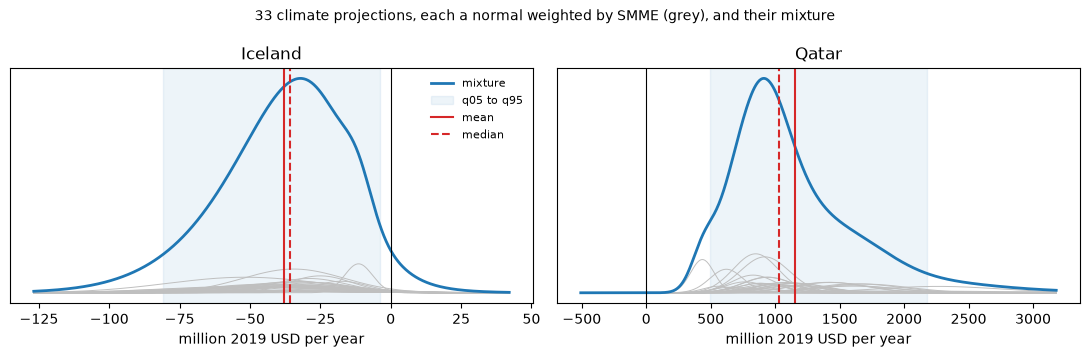

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (i, c) in zip(axes, enumerate(countries)):
    m, v = country_M[i] / 1e6, country_V[i] / 1e12
    lo, hi = result.loc[c, "q05"] / 1e6, result.loc[c, "q95"] / 1e6
    pad = 0.6 * (hi - lo)
    x = np.linspace(min(lo - pad, 0), max(hi + pad, 0), 600)
    parts = w[:, None] / w.sum() * norm.pdf(x[None, :], m[:, None], np.sqrt(v)[:, None])
    for p in parts:
        ax.plot(x, p, color="0.75", lw=0.7)
    ax.plot(x, parts.sum(axis=0), color="C0", lw=2, label="mixture")
    ax.axvspan(lo, hi, color="C0", alpha=0.08, label="q05 to q95")
    ax.axvline(result.loc[c, "mean"] / 1e6, color="C3", lw=1.5, label="mean")
    ax.axvline(result.loc[c, "q50"] / 1e6, color="C3", lw=1.5, ls="--", label="median")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(data.COUNTRIES[c])
    ax.set_xlabel("million 2019 USD per year")
    ax.set_yticks([])
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("33 climate projections, each a normal weighted by SMME (grey), and their mixture", fontsize=10)
fig.tight_layout()

In [17]:
# Iceland's provinces
(by_province.loc["ISL", cols] / 1e6).round(2)

,mean,q50,q05,q17,q83,q95
ID_1,,,,,,
1,-1.86,-1.75,-3.85,-2.88,-0.84,-0.28
2,-3.62,-3.43,-7.40,-5.57,-1.65,-0.55
3,-22.12,-20.74,-48.29,-35.46,-8.51,-1.56
4,-0.90,-0.85,-1.85,-1.39,-0.41,-0.14
5,-3.36,-3.19,-6.88,-5.18,-1.54,-0.51
6,-3.40,-3.22,-6.96,-5.24,-1.55,-0.52
7,-0.85,-0.81,-1.74,-1.31,-0.39,-0.13
8,-1.89,-1.78,-3.89,-2.92,-0.85,-0.27


## 9. What summing the variances would have done

The same mixture, built with each projection's variance taken as the sum of its regions' variances instead of at the target.

In [18]:
summed_V = np.stack([
    [sum((window_grad[g] * DOLLARS)[:, r] @ vcv @ (window_grad[g] * DOLLARS)[:, r]
         for r in np.flatnonzero(iso == c)) for c in countries]
    for g in GCMS], axis=-1)
shortcut = mixture(country_M, summed_V).set_index(pd.Index(countries, name="ISO"))
pd.DataFrame({
    "q05 to q95, at the target": (result["q95"] - result["q05"]) / 1e6,
    "q05 to q95, summed variances": (shortcut["q95"] - shortcut["q05"]) / 1e6,
}).rename(index=data.COUNTRIES).round(1)

,"q05 to q95, at the target","q05 to q95, summed variances"
ISO,,
Iceland,76.8,59.0
Qatar,1676.1,1585.9


The shortcut narrows both uncertainty ranges, more in Iceland than in Qatar, where differences between climate projections dominate. It understates the uncertainty within each projection but leaves the differences between projections unchanged, so its effect on mixture percentiles is smaller where projections disagree more.

## 10. Map

The map highlights regional contrasts in Chile and Austria, where changes are less uniform than in Qatar and Iceland. By the end of the century, Chile shows a north–south contrast, while Austria shows opposing changes in Tirol and Vienna.

Only means are mapped, computed from the median leaves and aggregated across regions (Section 7). Percentiles require gradients, retained only for Qatar and Iceland. Per capita values divide window-mean dollars by window-mean population, using the same aggregation weights for both.

In [19]:
with netCDF4.Dataset(data.median_path(GCMS[0])) as ds:
    map_regions = [str(r) for r in ds.variables["regions"][:] if str(r)[:3] in data.MAP_COUNTRIES]
population = pd.read_parquet(data.POPULATION).pivot(index="year", columns="hierid", values="pop")
prices = pd.read_parquet(data.PRICE).pivot(index="year", columns="country", values="price")
people = population.loc[YEARS, map_regions].to_numpy()
map_scale = people * prices.loc[YEARS, [r[:3] for r in map_regions]].to_numpy()

mixed = sum(wi * median_effect(g, map_regions) for wi, g in zip(w, GCMS)) / w.sum()
valued = mixed * map_scale * DOLLARS           # year, region; mixture mean in dollars
map_weights = {level: cilreg.WeightsArtifact.load(p) for level, p in data.WEIGHTS.items()}

per_person = {}
for window in data.WINDOWS:
    both = np.stack([cilreg.window_gradient(valued, YEARS, window),
                     cilreg.window_gradient(people, YEARS, window)])   # aggregated together
    levels = {"impact_region": pd.DataFrame({"hierid": map_regions, "dollars": both[0],
                                             "people": both[1]})}
    for level in ("adm1", "adm2"):
        t, A = cilreg.aggregate_gradient(map_weights[level], map_regions, both)
        levels[level] = t.assign(dollars=A[:, 0], people=A[:, 1])
    levels["adm0"] = levels["adm1"].groupby("ISO", as_index=False)[["dollars", "people"]].sum()
    for level, f in levels.items():
        per_person[level, window] = f.assign(usd_per_person=f["dollars"] / f["people"])

pd.DataFrame({f"{lo} to {hi}": per_person["adm0", (lo, hi)].set_index("ISO")["usd_per_person"]
              for lo, hi in data.WINDOWS}).rename(index=data.MAP_COUNTRIES).round(1)

,2020 to 2039,2080 to 2099
ISO,,
Austria,-3.7,3.7
Chile,0.9,25.5


Each period uses a separate colour scale, shared across countries and aggregation levels, to reflect the larger changes by the end of the century.

In [20]:
import geopandas as gpd
from matplotlib.colors import TwoSlopeNorm

LEVELS = {"adm0": ["ISO"], "impact_region": ["hierid"], "adm1": ["ISO", "ID_1"],
          "adm2": ["ISO", "ID_1", "ID_2"]}
LABELS = {"adm0": "country", "impact_region": "impact region", "adm1": "adm1", "adm2": "adm2"}
outlines = {level: gpd.read_parquet(p) for level, p in data.OUTLINES.items()}
outlines["impact_region"]["ISO"] = outlines["impact_region"]["hierid"].str[:3]

norms = {}
for window in data.WINDOWS:
    v = pd.concat([per_person[level, window]["usd_per_person"] for level in LEVELS])
    norms[window] = TwoSlopeNorm(vmin=min(v.min(), -1e-9), vcenter=0, vmax=max(v.max(), 1e-9))

def draw(ax, iso, level, window):
    shapes = outlines[level][outlines[level]["ISO"] == iso]
    f = shapes.merge(per_person[level, window], on=LEVELS[level], validate="1:1")
    assert len(f) == len(shapes)
    # no edges for the country, whose outline is in many pieces
    f.plot(column="usd_per_person", cmap="RdBu_r", norm=norms[window], ax=ax,
           edgecolor="none" if level == "adm0" else "white", linewidth=0.2)
    ax.set_xticks([]); ax.set_yticks([])
    for side in ax.spines.values():
        side.set_visible(False)

def colorbars(fig, axes_by_window, **kw):
    for window, axes in axes_by_window.items():
        fig.colorbar(plt.cm.ScalarMappable(norm=norms[window], cmap="RdBu_r"), ax=axes,
                     label="2019 USD per person per year", **kw)

TITLE = "Mean change in electricity spending per person, the mean of the mixture of 33 climate projections"

Chile's panels stop at 76° W. That leaves out one adm2 unit and one impact region, both made of Easter Island and the Juan Fernández Islands, far out in the Pacific.

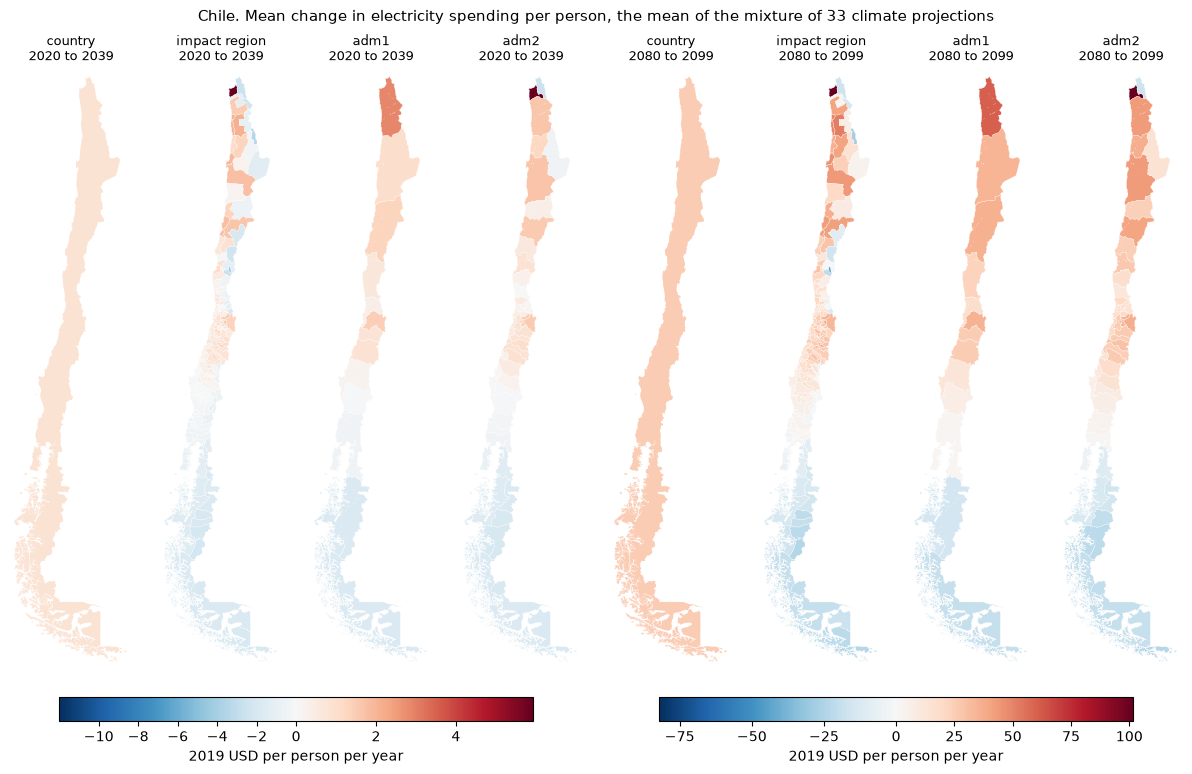

In [21]:
fig, axes = plt.subplots(1, 8, figsize=(12, 7.6), layout="constrained")
for i, window in enumerate(data.WINDOWS):
    for j, level in enumerate(LEVELS):
        ax = axes[4 * i + j]
        draw(ax, "CHL", level, window)
        ax.set_xlim(-76, -66)
        ax.set_ylim(-56, -17)
        ax.set_title(f"{LABELS[level]}\n{window[0]} to {window[1]}", fontsize=9)
colorbars(fig, {window: axes[4 * i:4 * i + 4] for i, window in enumerate(data.WINDOWS)},
          orientation="horizontal", shrink=0.8)
fig.suptitle(f"Chile. {TITLE}", fontsize=11)
plt.show()

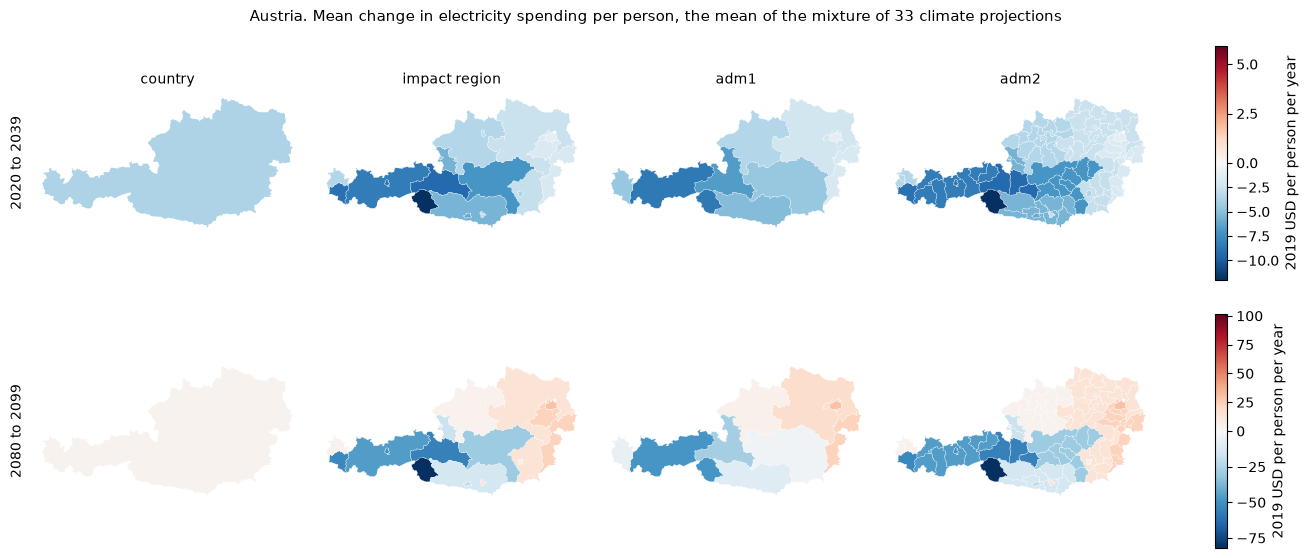

In [22]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5.6), layout="constrained")
for i, window in enumerate(data.WINDOWS):
    for j, level in enumerate(LEVELS):
        draw(axes[i, j], "AUT", level, window)
        if i == 0:
            axes[i, j].set_title(LABELS[level], fontsize=10)
    axes[i, 0].set_ylabel(f"{window[0]} to {window[1]}")
colorbars(fig, {window: axes[i] for i, window in enumerate(data.WINDOWS)}, shrink=0.9)
fig.suptitle(f"Austria. {TITLE}", fontsize=11)
plt.show()